# LoRA vs Prompt-Tuning for Low-Resource Sentiment Classification
**Full fine-tuning vs LoRA vs prompt-tuning on a small multilingual encoder (IndicBERT v2 / mBERT), Gujarati and Marathi, as the amount of training data shrinks.**

### Research questions
1. How do full fine-tuning, LoRA and prompt-tuning compare in macro-F1 when training data is plentiful (about 500 examples)?
2. How does each method *degrade* as training data is cut down (500 → 256 → 128 → 64 → 32 → 16)?
3. What does each method cost (trainable parameters, time, GPU memory)?
4. Are the conclusions the same for Gujarati and Marathi?

### Data
`ai4bharat/IndicSentiment` (IndicXTREME). It has only a validation split (156 rows) and a test split (1000 rows) per language, **no train split**. So the 998 labelled test rows are split once (fixed seed) into a 500-row **training pool** and a 498-row **held-out test set**, and the official validation set (156 rows) is used as **dev**. The data is n-way parallel (the same reviews in every language), so Gujarati and Marathi get identical splits.

### Methods
| Name | What is trained |
|---|---|
| `full` | every weight |
| `lora` | low-rank adapters (r=8) on the attention query and value matrices, plus the pooler and classifier head |
| `prompt` | 20 learned virtual-token embeddings, plus the pooler and classifier head |
| `probe` | frozen encoder, only the pooler and classifier head (a floor baseline) |

### How to run
1. Runtime → Change runtime type → **T4 GPU**.
2. Keep `SMOKE_TEST = True` and run all cells top to bottom. This finishes in a few minutes and checks that everything works.
3. Set `SMOKE_TEST = False`, restart the runtime, and run again. Results are appended to `results.csv` after every run, so if Colab disconnects you can re-run and it **resumes where it stopped**.

## 1. Setup

In [ ]:
%pip -q install -U transformers peft accelerate scikit-learn huggingface_hub scipy sentencepiece

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.4.0 which is incompatible.


In [ ]:
import os, json, gc, time, math, random, warnings
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from peft import LoraConfig, PromptTuningConfig, TaskType, get_peft_model
from huggingface_hub import hf_hub_download

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------ switches
SMOKE_TEST = True          # True = tiny run to check the pipeline; False = real experiment

# ------------------------------------------------------------------ where to save results
try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/lora_vs_prompt_sentiment"   # survives Colab disconnects
except ImportError:
    OUT_DIR = "./outputs"
os.makedirs(OUT_DIR, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"                                       # fp16 mixed precision on GPU
print("device:", DEVICE, "| results folder:", OUT_DIR)

Mounted at /content/drive
device: cuda | results folder: /content/drive/MyDrive/lora_vs_prompt_sentiment


### Experiment configuration
Everything you may want to change is in this one cell.

In [ ]:
MODELS = {
    "indicbert2": "ai4bharat/IndicBERTv2-mlm-only",   # main model
    "mbert": "bert-base-multilingual-cased",          # baseline model
}
RUN_MODELS = ["indicbert2"]          # add "mbert" here later if you have time
LANGS = ["gu", "mr"]
METHODS = ["full", "lora", "prompt", "probe"]

TRAIN_POOL = 500                     # size of the training pool carved out of the official test split
MAX_LEN, BATCH, EPOCHS = 128, 16, 10
SPLIT_SEED = 42                      # fixes the train/test split (never changes)

# Number of optimiser steps is max(EPOCHS * steps_per_epoch, MIN_STEPS[method]).
# The minimum matters for tiny training sets, and prompt-tuning is known to need more steps.
MIN_STEPS = {"full": 100, "lora": 150, "prompt": 300, "probe": 150}
LR_GRID = {                          # learning rates tried on the dev set (see section 5)
    "full":   [1e-5, 2e-5, 5e-5],
    "lora":   [1e-4, 3e-4, 1e-3],
    "prompt": [1e-2, 3e-2, 1e-1],
    "probe":  [1e-3, 3e-3, 1e-2],
}
TUNE_N = 128                         # training-set size used for the learning-rate search

SIZES = [16, 32, 64, 128, 256, TRAIN_POOL]
SEEDS = [0, 1, 2]                    # use [0,1,2,3,4] if you have time: small-data results are noisy

if SMOKE_TEST:                       # tiny version, just to check that the code runs
    SIZES, SEEDS = [16, 64], [0]
    MIN_STEPS = {k: 10 for k in MIN_STEPS}
    LR_GRID = {"full": [2e-5], "lora": [3e-4], "prompt": [3e-2], "probe": [3e-3]}
    TUNE_N = 64
    RESULTS_NAME, TUNE_NAME = "results_smoke.csv", "best_lr_smoke.json"
else:
    RESULTS_NAME, TUNE_NAME = "results.csv", "best_lr.json"

RESULTS_PATH = os.path.join(OUT_DIR, RESULTS_NAME)
TUNE_PATH = os.path.join(OUT_DIR, TUNE_NAME)
print("sizes:", SIZES, "| seeds:", SEEDS, "| runs per (model, language):", len(METHODS) * len(SIZES) * len(SEEDS))

sizes: [16, 64] | seeds: [0] | runs per (model, language): 8


## 2. Data
IndicSentiment is stored as one JSON file per language and split. Each row has the review in the target language (`INDIC REVIEW`), the English original (`ENGLISH REVIEW`) and the label (`LABEL`).

In [ ]:
REPO = "ai4bharat/IndicSentiment"
LABEL2ID = {"Negative": 0, "Positive": 1}

def read_split(lang, split):
    path = hf_hub_download(REPO, f"data/{split}/{lang}.json", repo_type="dataset")
    txt = open(path, encoding="utf-8").read()
    try:
        d = json.loads(txt)
        return d if isinstance(d, list) else list(d.values())
    except json.JSONDecodeError:                    # JSON-lines fallback
        return [json.loads(l) for l in txt.splitlines() if l.strip()]

In [ ]:
raw = {lang: {s: read_split(lang, s) for s in ["validation", "test"]} for lang in LANGS}

# Check 1: is the data n-way parallel (same English review at the same row in every language)?
ref = LANGS[0]
for lang in LANGS[1:]:
    for s in ["validation", "test"]:
        same = all(a["ENGLISH REVIEW"] == b["ENGLISH REVIEW"] for a, b in zip(raw[ref][s], raw[lang][s]))
        print(f"{ref} vs {lang} [{s}] rows aligned:", same and len(raw[ref][s]) == len(raw[lang][s]))

gu.json:   0%|          | 0.00/177k [00:00<?, ?B/s]

gu.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

mr.json:   0%|          | 0.00/183k [00:00<?, ?B/s]

mr.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

gu vs mr [validation] rows aligned: True
gu vs mr [test] rows aligned: True


In [ ]:
def make_splits(lang):
    # Build train pool / held-out test / dev for one language.
    rows = raw[lang]["test"]
    keep = [i for i, r in enumerate(rows) if r["LABEL"] in LABEL2ID]          # drops rows with a missing label
    y = [LABEL2ID[rows[i]["LABEL"]] for i in keep]
    tr_idx, te_idx = train_test_split(keep, train_size=TRAIN_POOL, stratify=y, random_state=SPLIT_SEED)
    dev_rows = [r for r in raw[lang]["validation"] if r["LABEL"] in LABEL2ID]
    pick = lambda rs: ([r["INDIC REVIEW"] for r in rs], [LABEL2ID[r["LABEL"]] for r in rs])
    return {"train": pick([rows[i] for i in tr_idx]), "test": pick([rows[i] for i in te_idx]),
            "dev": pick(dev_rows), "train_idx": sorted(tr_idx), "test_idx": sorted(te_idx)}

SPLITS = {lang: make_splits(lang) for lang in LANGS}

for lang in LANGS:
    s = SPLITS[lang]
    print(lang, {k: len(s[k][0]) for k in ["train", "test", "dev"]},
          "| train positive rate: %.2f" % np.mean(s["train"][1]),
          "| exact-text overlap train/test:", len(set(s["train"][0]) & set(s["test"][0])))

# Check 2: Gujarati and Marathi must use exactly the same reviews in each split
if len(LANGS) > 1:
    print("identical split across languages:", all(SPLITS[l]["train_idx"] == SPLITS[ref]["train_idx"] for l in LANGS))

gu {'train': 500, 'test': 498, 'dev': 156} | train positive rate: 0.51 | exact-text overlap train/test: 0
mr {'train': 500, 'test': 498, 'dev': 156} | train positive rate: 0.51 | exact-text overlap train/test: 0
identical split across languages: True


## 3. Tokenisation

In [ ]:
TOK = {k: AutoTokenizer.from_pretrained(MODELS[k]) for k in RUN_MODELS}

def encode(model_key, texts, labels):
    enc = TOK[model_key](texts, truncation=True, max_length=MAX_LEN)
    return [dict({k: enc[k][i] for k in enc.keys()}, labels=labels[i]) for i in range(len(texts))]

ENC = {(mk, lang, split): encode(mk, *SPLITS[lang][split])
       for mk in RUN_MODELS for lang in LANGS for split in ["train", "dev", "test"]}

# How long are the reviews in tokens? (tells us whether MAX_LEN truncates anything)
for mk in RUN_MODELS:
    for lang in LANGS:
        lens = [len(f["input_ids"]) for f in ENC[(mk, lang, "train")]]
        print(mk, lang, "token length p50/p95/max:", int(np.percentile(lens, 50)), int(np.percentile(lens, 95)), max(lens))

config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 7.75MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

indicbert2 gu token length p50/p95/max: 33 63 117
indicbert2 mr token length p50/p95/max: 31 58 107


## 4. Models: the four training methods
All four use the same pretrained encoder with a 2-class classification head. They differ only in **which parameters are trained**.

* **Pooler:** BERT's classification head reads the pooled `[CLS]` vector. For some checkpoints the pooler is not pretrained, so for every method except `full` we also train the pooler. This keeps the comparison fair, and it is included in the trainable-parameter counts.
* **Prompt-tuning** adds 20 learnable "virtual token" embeddings in front of the input. Everything else in the encoder is frozen.

In [ ]:
def build_model(model_key, method):
    base = AutoModelForSequenceClassification.from_pretrained(MODELS[model_key], num_labels=2)
    if method == "full":
        model = base
    elif method == "probe":
        for p in base.parameters():
            p.requires_grad = False
        model = base
    elif method == "lora":
        cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=8, lora_alpha=16, lora_dropout=0.1,
                         target_modules=["query", "value"])
        model = get_peft_model(base, cfg)
    elif method == "prompt":
        cfg = PromptTuningConfig(task_type=TaskType.SEQ_CLS, num_virtual_tokens=20)
        model = get_peft_model(base, cfg)
    else:
        raise ValueError(method)
    # head = pooler + classifier is trained for every method
    for name, p in model.named_parameters():
        if "pooler" in name or "classifier" in name:
            p.requires_grad = True
    return model

def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

Quick look at how many parameters each method actually trains:

In [ ]:
%pip -q uninstall -y torchao

In [ ]:
for method in METHODS:
    m = build_model(RUN_MODELS[0], method)
    tr, tot = count_params(m)
    print(f"{method:7s} trainable = {tr:>12,d}  ({100 * tr / tot:6.3f}% of {tot:,d})")
    del m
gc.collect()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-mlm-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

full    trainable =  278,042,882  (100.000% of 278,042,882)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-mlm-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

lora    trainable =      888,580  ( 0.319% of 278,339,332)


... (3 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-mlm-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

probe   trainable =      592,130  ( 0.213% of 278,042,882)


1734

## 5. Training and evaluation code
`train_run` trains one model once and returns its scores. A single custom loop is used for all methods, so every method gets exactly the same treatment (optimiser, schedule, batch size, mixed precision).

In [ ]:
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def evaluate(model, feats, tok):
    model.eval()
    loader = DataLoader(feats, batch_size=64, collate_fn=lambda b: tok.pad(b, return_tensors="pt"))
    preds = []
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items() if k != "labels"}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**batch).logits
        preds += logits.argmax(-1).tolist()
    y = [f["labels"] for f in feats]
    return accuracy_score(y, preds), f1_score(y, preds, average="macro")

def subsample(feats, n, seed):
    # class-balanced random subset of size n (different for every seed)
    if n >= len(feats):
        return feats
    idx, _ = train_test_split(list(range(len(feats))), train_size=n,
                              stratify=[f["labels"] for f in feats], random_state=seed)
    return [feats[i] for i in idx]

def train_run(model_key, lang, method, n, seed, lr, eval_split="test"):
    set_seed(seed)
    tok = TOK[model_key]
    feats = subsample(ENC[(model_key, lang, "train")], n, seed)
    n_actual = len(feats)

    model = build_model(model_key, method).to(DEVICE)
    trainable, total = count_params(model)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)

    bs = min(BATCH, n_actual)
    total_steps = max(EPOCHS * math.ceil(n_actual / bs), MIN_STEPS[method])
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loader = DataLoader(feats, batch_size=bs, shuffle=True, drop_last=False,
                        generator=torch.Generator().manual_seed(seed),
                        collate_fn=lambda b: tok.pad(b, return_tensors="pt"))

    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0, step = time.time(), 0
    model.train()
    while step < total_steps:
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**batch).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            step += 1
            if step >= total_steps:
                break
    train_time = time.time() - t0

    acc, f1 = evaluate(model, ENC[(model_key, lang, eval_split)], tok)
    peak_mb = torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else 0.0
    out = dict(model=model_key, lang=lang, method=method, n_train=n_actual, seed=seed, lr=lr,
               steps=total_steps, acc=acc, macro_f1=f1, trainable_params=trainable, total_params=total,
               train_time_s=round(train_time, 1), peak_mem_mb=round(peak_mb, 0))
    del model, opt, params, loader
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return out

### Learning-rate search (dev set only)
The right learning rate differs a lot between methods (prompt-tuning needs a much larger one than full fine-tuning). Using one shared value would unfairly handicap some methods. For each (model, language, method) we try a small grid at a fixed training size (`TUNE_N`), score on the **dev** set (never the test set) with one seed, and keep the best. The chosen value is then used for every training size.

In [ ]:
best_lr = json.load(open(TUNE_PATH)) if os.path.exists(TUNE_PATH) else {}

for mk in RUN_MODELS:
    for lang in LANGS:
        for method in METHODS:
            key = f"{mk}|{lang}|{method}"
            if key in best_lr:
                continue
            scores = {}
            for lr in LR_GRID[method]:
                r = train_run(mk, lang, method, TUNE_N, seed=0, lr=lr, eval_split="dev")
                scores[lr] = r["macro_f1"]
                print(f"{key} lr={lr:g} dev macro-F1={r['macro_f1']:.3f}")
            best_lr[key] = max(scores, key=scores.get)
            json.dump(best_lr, open(TUNE_PATH, "w"), indent=1)

print("\nchosen learning rates:")
for k, v in best_lr.items():
    print(" ", k, v)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-mlm-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

indicbert2|gu|full lr=2e-05 dev macro-F1=0.593


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-mlm-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

indicbert2|gu|lora lr=0.0003 dev macro-F1=0.653


... (14 outputs left out)

indicbert2|mr|prompt lr=0.03 dev macro-F1=0.651


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-mlm-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

indicbert2|mr|probe lr=0.003 dev macro-F1=0.678

chosen learning rates:
  indicbert2|gu|full 2e-05
  indicbert2|gu|lora 0.0003
  indicbert2|gu|prompt 0.03
  indicbert2|gu|probe 0.003
  indicbert2|mr|full 2e-05
  indicbert2|mr|lora 0.0003
  indicbert2|mr|prompt 0.03
  indicbert2|mr|probe 0.003


## 6. Main experiment
Loops over model × language × method × training size × seed, evaluates on the held-out **test** set, and appends one row per run to a CSV file. Finished runs are skipped, so the cell can be re-run after a disconnect.

In [ ]:
KEYS = ["model", "lang", "method", "n_train", "seed"]
done = set()
if os.path.exists(RESULTS_PATH):
    prev = pd.read_csv(RESULTS_PATH)
    done = set(map(tuple, prev[KEYS].values.tolist()))

grid = [(mk, lang, method, n, seed) for mk in RUN_MODELS for lang in LANGS
        for method in METHODS for n in SIZES for seed in SEEDS]
print(f"{len(grid)} runs in total, {len(done)} already finished")

for i, (mk, lang, method, n, seed) in enumerate(grid):
    n_eff = min(n, TRAIN_POOL)
    if (mk, lang, method, n_eff, seed) in done:
        continue
    r = train_run(mk, lang, method, n, seed, best_lr[f"{mk}|{lang}|{method}"], eval_split="test")
    pd.DataFrame([r]).to_csv(RESULTS_PATH, mode="a", header=not os.path.exists(RESULTS_PATH), index=False)
    print(f"[{i + 1}/{len(grid)}] {mk} {lang} {method:6s} n={n:3d} seed={seed}  "
          f"F1={r['macro_f1']:.3f} acc={r['acc']:.3f} ({r['train_time_s']}s)")
print("done")

16 runs in total, 0 already finished


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-mlm-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

[1/16] indicbert2 gu full   n= 16 seed=0  F1=0.461 acc=0.552 (1.8s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-mlm-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

... (39 outputs left out)

[15/16] indicbert2 mr probe  n= 16 seed=0  F1=0.548 acc=0.590 (0.3s)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: ai4bharat/IndicBERTv2-mlm-only
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those p

[16/16] indicbert2 mr probe  n= 64 seed=0  F1=0.671 acc=0.679 (0.8s)
done


## 7. Results and analysis

In [ ]:
import matplotlib.pyplot as plt
res = pd.read_csv(RESULTS_PATH)
agg = (res.groupby(["model", "lang", "method", "n_train"])
          .agg(f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"), acc_mean=("acc", "mean"), runs=("seed", "count"))
          .reset_index())
agg["f1_std"] = agg["f1_std"].fillna(0.0)

# Table 1: macro-F1 (mean ± std over seeds)
for (mk, lang), g in agg.groupby(["model", "lang"]):
    t = g.assign(txt=lambda d: d.f1_mean.map("{:.3f}".format) + " ± " + d.f1_std.map("{:.3f}".format)) \
         .pivot(index="method", columns="n_train", values="txt")
    print(f"\nMacro-F1  |  {mk}  |  {lang}")
    display(t) if "display" in globals() else print(t)


Macro-F1  |  indicbert2  |  gu
n_train             16             64
method                               
full     0.461 ± 0.000  0.653 ± 0.000
lora     0.503 ± 0.000  0.710 ± 0.000
probe    0.614 ± 0.000  0.729 ± 0.000
prompt   0.619 ± 0.000  0.638 ± 0.000

Macro-F1  |  indicbert2  |  mr
n_train             16             64
method                               
full     0.419 ± 0.000  0.700 ± 0.000
lora     0.557 ± 0.000  0.676 ± 0.000
probe    0.548 ± 0.000  0.671 ± 0.000
prompt   0.647 ± 0.000  0.693 ± 0.000


### Learning curves: macro-F1 against training-set size

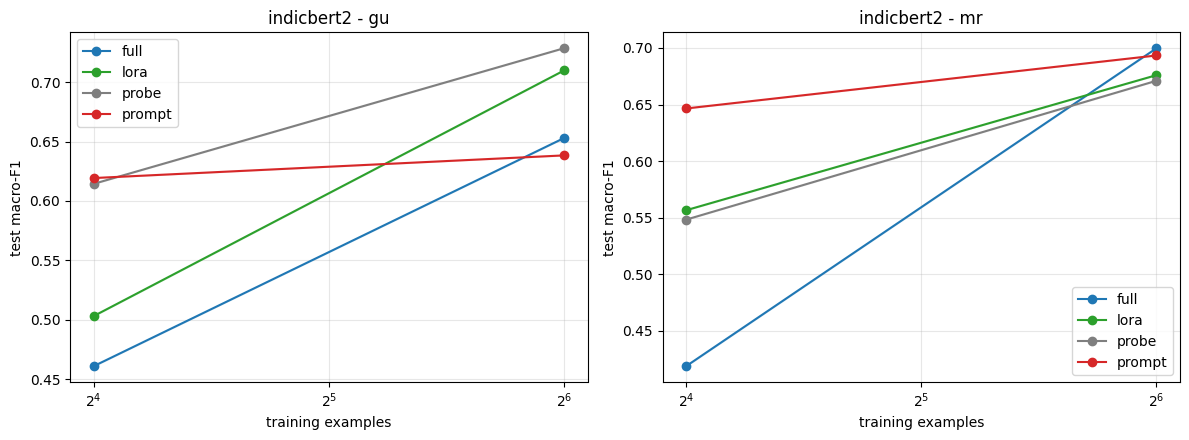

In [ ]:
colors = {"full": "tab:blue", "lora": "tab:green", "prompt": "tab:red", "probe": "tab:gray"}
groups = list(agg.groupby(["model", "lang"]))
fig, axes = plt.subplots(1, len(groups), figsize=(6 * len(groups), 4.5), squeeze=False)
for ax, ((mk, lang), g) in zip(axes[0], groups):
    for method, gm in g.groupby("method"):
        gm = gm.sort_values("n_train")
        ax.plot(gm.n_train, gm.f1_mean, marker="o", label=method, color=colors[method])
        ax.fill_between(gm.n_train, gm.f1_mean - gm.f1_std, gm.f1_mean + gm.f1_std, alpha=0.15, color=colors[method])
    ax.set_xscale("log", base=2); ax.set_xlabel("training examples"); ax.set_ylabel("test macro-F1")
    ax.set_title(f"{mk} - {lang}"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "learning_curves.png"), dpi=200); plt.show()

### Degradation: how much performance is kept as data shrinks?
*Retention* = macro-F1 at n examples ÷ macro-F1 of the **same method** with the full training pool. A method that keeps 95% of its performance with 64 examples degrades gracefully. A method with 70% does not.

*AULC* (area under the learning curve) summarises the whole curve in one number: the average macro-F1 across training sizes on a log₂ scale. Higher means better across the whole data range.

In [ ]:
full_n = agg.n_train.max()
base = agg[agg.n_train == full_n].set_index(["model", "lang", "method"]).f1_mean.rename("f1_full")
ret = agg.join(base, on=["model", "lang", "method"])
ret["retention"] = ret.f1_mean / ret.f1_full
for (mk, lang), g in ret.groupby(["model", "lang"]):
    print(f"\nRetention of full-data F1  |  {mk}  |  {lang}")
    print(g.pivot(index="method", columns="n_train", values="retention").round(3))

def aulc(g):
    g = g.sort_values("n_train"); x = np.log2(g.n_train.values); y = g.f1_mean.values
    return float(np.sum(np.diff(x) * (y[1:] + y[:-1]) / 2) / (x[-1] - x[0])) if len(x) > 1 else float("nan")
print("\nAULC (mean macro-F1 over the log-size axis)")
print(agg.groupby(["model", "lang", "method"]).apply(aulc).unstack("method").round(3))


Retention of full-data F1  |  indicbert2  |  gu
n_train     16   64
method             
full     0.706  1.0
lora     0.709  1.0
probe    0.843  1.0
prompt   0.970  1.0

Retention of full-data F1  |  indicbert2  |  mr
n_train     16   64
method             
full     0.598  1.0
lora     0.823  1.0
probe    0.817  1.0
prompt   0.932  1.0

AULC (mean macro-F1 over the log-size axis)
method            full   lora  probe  prompt
model      lang                             
indicbert2 gu    0.557  0.606  0.671   0.629
           mr    0.559  0.616  0.610   0.670


### Cost: trainable parameters, training time and GPU memory (at the largest training size)

In [ ]:
cost = (res[res.n_train == res.n_train.max()]
        .groupby(["model", "method"])
        .agg(trainable_params=("trainable_params", "first"), total_params=("total_params", "first"),
             train_time_s=("train_time_s", "mean"), peak_mem_mb=("peak_mem_mb", "mean")).reset_index())
cost["trainable_%"] = (100 * cost.trainable_params / cost.total_params).round(3)
print(cost.drop(columns="total_params").to_string(index=False))

     model method  trainable_params  train_time_s  peak_mem_mb  trainable_%
indicbert2   full         278042882          7.50       5364.0      100.000
indicbert2   lora            888580          2.05       1812.5        0.319
indicbert2  probe            592130          0.80       1268.0        0.213
indicbert2 prompt            609028          2.05       1817.0        0.219


### Are the differences between methods real?
Welch t-test on the per-seed macro-F1 scores at each training size. With only 3 seeds these tests have low power, so treat p-values as a rough guide. Where the methods differ by less than about one standard deviation, do **not** claim one is better.

In [ ]:
from scipy.stats import ttest_ind
pairs = [("lora", "full"), ("prompt", "full"), ("lora", "prompt")]
rows = []
for (mk, lang, n), g in res.groupby(["model", "lang", "n_train"]):
    for a, b in pairs:
        fa, fb = g[g.method == a].macro_f1.values, g[g.method == b].macro_f1.values
        if len(fa) >= 2 and len(fb) >= 2:
            rows.append(dict(model=mk, lang=lang, n_train=n, comparison=f"{a} vs {b}",
                             mean_diff=fa.mean() - fb.mean(), p_value=ttest_ind(fa, fb, equal_var=False).pvalue))
sig = pd.DataFrame(rows)
print(sig.round(4).to_string(index=False) if len(sig) else "need at least 2 seeds per method for t-tests")

need at least 2 seeds per method for t-tests


## 8. Discussion (fill in after the full run)
Answer each point using the tables and the figure above, and quote numbers.

1. **Full data:** Which method wins at ~500 examples, and by how much compared with the seed-to-seed std?
2. **Low data:** At which size, if any, does the ranking change? Does LoRA or prompt-tuning overtake full fine-tuning when data is scarce?
3. **Degradation:** Which method has the best retention at 16 and 32 examples?
4. **Cost:** What is the price in trainable parameters, time and memory for the accuracy that each method gives?
5. **Language:** Do Gujarati and Marathi show the same pattern? If not, what might explain the difference?
6. **Prompt-tuning:** Was it unstable (large std)? Did the learning-rate search matter?

### Limitations (keep these in the write-up)
* IndicSentiment is human-*translated* review text and not naturally written Gujarati or Marathi. Results may not carry over to real social-media text.
* The training pool and test set both come from the released IndicSentiment test split and have only ~500 examples each, so differences of 1-2 points are within noise.
* Binary labels only (positive/negative). Hyper-parameters were tuned once at n=128 and reused for all sizes.
* One encoder size (base). Findings for LoRA and prompt-tuning can change with model scale.

### Suggested paper / report structure
Abstract · Introduction · Related work (LoRA, prompt-tuning, IndicBERT, IndicXTREME) · Data and splits · Methods · Experimental setup · Results (Table 1, learning curves, retention, cost, significance) · Discussion · Limitations · Conclusion

In [ ]:
# Parameters that belong to the method itself (trainable minus the shared head that the probe also trains)
probe_params = res[res.method == "probe"].groupby("model").trainable_params.first()

cost["method_specific_params"] = cost.apply(
    lambda r: r.trainable_params if r.method == "full" else r.trainable_params - probe_params[r.model], axis=1)
cost["method_specific_%"] = (100 * cost.method_specific_params / cost.total_params).round(4)

print(cost[["model", "method", "trainable_params", "method_specific_params",
            "method_specific_%", "train_time_s", "peak_mem_mb"]].to_string(index=False))

     model method  trainable_params  method_specific_params  method_specific_%  train_time_s  peak_mem_mb
indicbert2   full         278042882               278042882           100.0000          7.50       5364.0
indicbert2   lora            888580                  296450             0.1065          2.05       1812.5
indicbert2  probe            592130                       0             0.0000          0.80       1268.0
indicbert2 prompt            609028                   16898             0.0061          2.05       1817.0


In [ ]:
#Part 1: Fix parameter counting and verify
#1.1: check that the earlier cells have been run

needed = ["raw", "SPLITS", "ENC", "TOK", "train_run", "evaluate", "subsample", "set_seed",
          "count_params", "MODELS", "RUN_MODELS", "LANGS", "METHODS", "TRAIN_POOL", "OUT_DIR",
          "DEVICE", "EPOCHS", "LR_GRID", "MIN_STEPS"]
missing = [n for n in needed if n not in globals()]
assert not missing, f"Run the earlier setup cells first. Missing: {missing}"
assert DEVICE == "cuda", "Switch the runtime to a T4 GPU (Runtime > Change runtime type)."

# hide the long 'LOAD REPORT' tables that appear every time a model loads
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
print("ready")

ready


In [ ]:
#1.2: corrected build_model
def build_model(model_key, method):
    base = AutoModelForSequenceClassification.from_pretrained(MODELS[model_key], num_labels=2)
    if method == "full":
        model = base
    elif method == "probe":
        for p in base.parameters():
            p.requires_grad = False
        model = base
    elif method == "lora":
        cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=8, lora_alpha=16, lora_dropout=0.1,
                         target_modules=["query", "value"])
        model = get_peft_model(base, cfg)
    elif method == "prompt":
        cfg = PromptTuningConfig(task_type=TaskType.SEQ_CLS, num_virtual_tokens=20)
        model = get_peft_model(base, cfg)
    else:
        raise ValueError(method)
    # train the head (pooler + classifier) in every method, but not PEFT's frozen backup copy
    for name, p in model.named_parameters():
        if ("pooler" in name or "classifier" in name) and "original_module" not in name:
            p.requires_grad = True
    return model

In [ ]:
#1.3: verify the counts
counts = {}
for method in METHODS:
    m = build_model(RUN_MODELS[0], method)
    counts[method] = count_params(m)
    del m; gc.collect(); torch.cuda.empty_cache()

probe_tr = counts["probe"][0]
for method, (tr, tot) in counts.items():
    specific = tr if method == "full" else tr - probe_tr
    print(f"{method:7s} trainable = {tr:>12,d} | method-specific = {specific:>12,d} ({100 * specific / tot:.4f}%)")

# expected for IndicBERT v2: LoRA adapters = 294,912 and 20 prompt tokens x 768 = 15,360
if RUN_MODELS[0] == "indicbert2":
    ok = (counts["lora"][0] - probe_tr == 294_912) and (counts["prompt"][0] - probe_tr == 15_360)
    print("\nparameter counts as expected:", ok)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

full    trainable =  278,042,882 | method-specific =  278,042,882 (100.0000%)
lora    trainable =      887,042 | method-specific =      294,912 (0.1060%)
prompt  trainable =      607,490 | method-specific =       15,360 (0.0055%)
probe   trainable =      592,130 | method-specific =            0 (0.0000%)

parameter counts as expected: True


In [ ]:
#Part 2: Real experiment configuration
SMOKE_TEST = False
SIZES = [16, 32, 64, 128, 256, TRAIN_POOL]
SEEDS = [0, 1, 2]                      # use [0, 1, 2, 3, 4] if you have time
MIN_STEPS = {"full": 100, "lora": 150, "prompt": 300, "probe": 150}
LR_GRID = {
    "full":   [1e-5, 2e-5, 5e-5],
    "lora":   [1e-4, 3e-4, 1e-3],
    "prompt": [1e-2, 3e-2, 1e-1],
    "probe":  [1e-3, 3e-3, 1e-2],
}
TUNE_N = 128
RESULTS_PATH = os.path.join(OUT_DIR, "results.csv")        # new files, separate from the smoke test
TUNE_PATH = os.path.join(OUT_DIR, "best_lr.json")

n_runs = len(RUN_MODELS) * len(LANGS) * len(METHODS) * len(SIZES) * len(SEEDS)
print(f"{n_runs} runs planned | sizes {SIZES} | seeds {SEEDS}")
print("results ->", RESULTS_PATH)

144 runs planned | sizes [16, 32, 64, 128, 256, 500] | seeds [0, 1, 2]
results -> /content/drive/MyDrive/lora_vs_prompt_sentiment/results.csv


In [ ]:
#Part 3: Learning-rate search (dev set only)

best_lr = json.load(open(TUNE_PATH)) if os.path.exists(TUNE_PATH) else {}

for mk in RUN_MODELS:
    for lang in LANGS:
        for method in METHODS:
            key = f"{mk}|{lang}|{method}"
            if key in best_lr:
                continue
            scores = {}
            for lr in LR_GRID[method]:
                r = train_run(mk, lang, method, TUNE_N, seed=0, lr=lr, eval_split="dev")
                scores[lr] = r["macro_f1"]
                print(f"{key}  lr={lr:g}  dev macro-F1={r['macro_f1']:.3f}")
            best_lr[key] = max(scores, key=scores.get)
            json.dump(best_lr, open(TUNE_PATH, "w"), indent=1)

print("\nchosen learning rates (flag = best value sits at the edge of its grid):")
for key, lr in best_lr.items():
    grid = sorted(LR_GRID[key.split("|")[2]])
    flag = "  <-- at the edge, consider widening the grid" if lr in (grid[0], grid[-1]) else ""
    print(f"  {key:28s} {lr:g}{flag}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

indicbert2|gu|full  lr=1e-05  dev macro-F1=0.738


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

indicbert2|gu|full  lr=2e-05  dev macro-F1=0.923


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

indicbert2|gu|full  lr=5e-05  dev macro-F1=0.910


... (38 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

indicbert2|mr|probe  lr=0.003  dev macro-F1=0.833


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

indicbert2|mr|probe  lr=0.01  dev macro-F1=0.840

chosen learning rates (flag = best value sits at the edge of its grid):
  indicbert2|gu|full           2e-05
  indicbert2|gu|lora           0.0003
  indicbert2|gu|prompt         0.03
  indicbert2|gu|probe          0.001  <-- at the edge, consider widening the grid
  indicbert2|mr|full           5e-05  <-- at the edge, consider widening the grid
  indicbert2|mr|lora           0.001  <-- at the edge, consider widening the grid
  indicbert2|mr|prompt         0.1  <-- at the edge, consider widening the grid
  indicbert2|mr|probe          0.01  <-- at the edge, consider widening the grid


In [ ]:
#Part 4: Main experiment (resumable)
KEYS = ["model", "lang", "method", "n_train", "seed"]
done = set()
if os.path.exists(RESULTS_PATH):
    prev = pd.read_csv(RESULTS_PATH)
    done = set(map(tuple, prev[KEYS].values.tolist()))

grid = [(mk, lang, method, n, seed) for mk in RUN_MODELS for lang in LANGS
        for method in METHODS for n in SIZES for seed in SEEDS]
todo = [g for g in grid if (g[0], g[1], g[2], min(g[3], TRAIN_POOL), g[4]) not in done]
print(f"{len(grid)} runs in total | {len(grid) - len(todo)} already finished | {len(todo)} to do")

failed, t_start = [], time.time()
for i, (mk, lang, method, n, seed) in enumerate(todo):
    try:
        r = train_run(mk, lang, method, n, seed, best_lr[f"{mk}|{lang}|{method}"], eval_split="test")
    except Exception as e:                                   # keep going if one run fails
        failed.append((mk, lang, method, n, seed, repr(e)[:200]))
        print(f"FAILED {mk} {lang} {method} n={n} seed={seed}: {repr(e)[:200]}")
        gc.collect(); torch.cuda.empty_cache()
        continue
    pd.DataFrame([r]).to_csv(RESULTS_PATH, mode="a", header=not os.path.exists(RESULTS_PATH), index=False)
    elapsed = time.time() - t_start
    eta = elapsed / (i + 1) * (len(todo) - i - 1) / 60
    print(f"[{i + 1}/{len(todo)}] {mk} {lang} {method:6s} n={n:3d} seed={seed}  "
          f"F1={r['macro_f1']:.3f} acc={r['acc']:.3f} ({r['train_time_s']}s)  ~{eta:.0f} min left")

print("\nfinished.", f"{len(failed)} failed runs" if failed else "no failures")
for f in failed:
    print(f)

144 runs in total | 0 already finished | 144 to do


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[1/144] indicbert2 gu full   n= 16 seed=0  F1=0.691 acc=0.691 (19.1s)  ~50 min left


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[2/144] indicbert2 gu full   n= 16 seed=1  F1=0.688 acc=0.697 (16.6s)  ~46 min left


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (279 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[143/144] indicbert2 mr probe  n=500 seed=1  F1=0.871 acc=0.871 (6.0s)  ~0 min left


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[144/144] indicbert2 mr probe  n=500 seed=2  F1=0.884 acc=0.884 (5.9s)  ~0 min left

finished. no failures


In [ ]:
#Part 5: Results and analysis
#5.1: load results and show the macro-F1 table

import matplotlib.pyplot as plt
from IPython.display import display

res = pd.read_csv(RESULTS_PATH)
print("runs completed:", len(res))
agg = (res.groupby(["model", "lang", "method", "n_train"])
          .agg(f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
               acc_mean=("acc", "mean"), runs=("seed", "count")).reset_index())
agg["f1_std"] = agg["f1_std"].fillna(0.0)
agg.to_csv(os.path.join(OUT_DIR, "summary_macro_f1.csv"), index=False)

for (mk, lang), g in agg.groupby(["model", "lang"]):
    t = (g.assign(txt=lambda d: d.f1_mean.map("{:.3f}".format) + " ± " + d.f1_std.map("{:.3f}".format))
          .pivot(index="method", columns="n_train", values="txt"))
    print(f"\nMacro-F1 (mean ± std over seeds) | {mk} | {lang}")
    display(t)

runs completed: 144

Macro-F1 (mean ± std over seeds) | indicbert2 | gu


n_train,16,32,64,128,256,500
method,,,,,,
full,0.683 ± 0.012,0.719 ± 0.031,0.889 ± 0.052,0.941 ± 0.013,0.958 ± 0.012,0.957 ± 0.006
lora,0.684 ± 0.042,0.701 ± 0.028,0.882 ± 0.052,0.947 ± 0.015,0.957 ± 0.003,0.956 ± 0.004
probe,0.621 ± 0.017,0.651 ± 0.019,0.764 ± 0.028,0.830 ± 0.017,0.821 ± 0.021,0.853 ± 0.006
prompt,0.634 ± 0.024,0.590 ± 0.220,0.797 ± 0.039,0.834 ± 0.061,0.879 ± 0.032,0.782 ± 0.210



Macro-F1 (mean ± std over seeds) | indicbert2 | mr


n_train,16,32,64,128,256,500
method,,,,,,
full,0.700 ± 0.014,0.818 ± 0.072,0.903 ± 0.035,0.936 ± 0.007,0.968 ± 0.002,0.969 ± 0.001
lora,0.640 ± 0.099,0.809 ± 0.121,0.905 ± 0.023,0.950 ± 0.014,0.969 ± 0.004,0.964 ± 0.007
probe,0.623 ± 0.037,0.673 ± 0.029,0.772 ± 0.018,0.806 ± 0.049,0.844 ± 0.003,0.881 ± 0.009
prompt,0.639 ± 0.014,0.743 ± 0.104,0.785 ± 0.050,0.736 ± 0.173,0.687 ± 0.266,0.777 ± 0.118


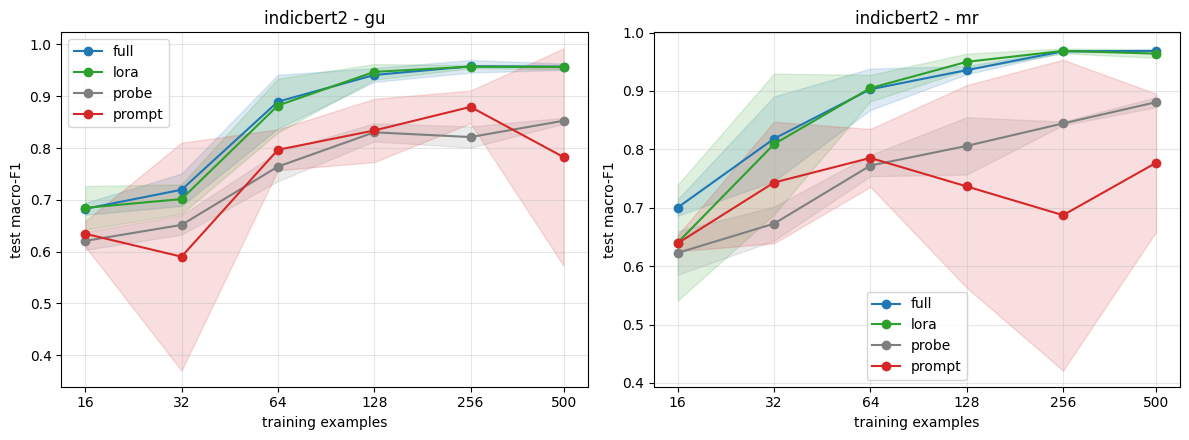

In [ ]:
#5.2: learning curves

colors = {"full": "tab:blue", "lora": "tab:green", "prompt": "tab:red", "probe": "tab:gray"}
groups = list(agg.groupby(["model", "lang"]))
fig, axes = plt.subplots(1, len(groups), figsize=(6 * len(groups), 4.5), squeeze=False)
for ax, ((mk, lang), g) in zip(axes[0], groups):
    for method, gm in g.groupby("method"):
        gm = gm.sort_values("n_train")
        ax.plot(gm.n_train, gm.f1_mean, marker="o", label=method, color=colors[method])
        ax.fill_between(gm.n_train, gm.f1_mean - gm.f1_std, gm.f1_mean + gm.f1_std,
                        alpha=0.15, color=colors[method])
    ax.set_xscale("log", base=2)
    ax.set_xticks(sorted(g.n_train.unique())); ax.set_xticklabels(sorted(g.n_train.unique()))
    ax.set_xlabel("training examples"); ax.set_ylabel("test macro-F1")
    ax.set_title(f"{mk} - {lang}"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "learning_curves.png"), dpi=200)
plt.show()

In [ ]:
#5.3: degradation (retention and AULC)

full_n = agg.n_train.max()
base = agg[agg.n_train == full_n].set_index(["model", "lang", "method"]).f1_mean.rename("f1_full")
ret = agg.join(base, on=["model", "lang", "method"])
ret["retention"] = ret.f1_mean / ret.f1_full
ret.to_csv(os.path.join(OUT_DIR, "retention.csv"), index=False)

for (mk, lang), g in ret.groupby(["model", "lang"]):
    print(f"\nRetention of own full-data F1 (n={full_n}) | {mk} | {lang}")
    display(g.pivot(index="method", columns="n_train", values="retention").round(3))

def aulc(g):
    g = g.sort_values("n_train")
    x, y = np.log2(g.n_train.values), g.f1_mean.values
    return float(np.sum(np.diff(x) * (y[1:] + y[:-1]) / 2) / (x[-1] - x[0])) if len(x) > 1 else float("nan")

print("\nAULC: mean macro-F1 across training sizes (log scale), higher is better")
aulc_table = agg.groupby(["model", "lang", "method"]).apply(aulc).unstack("method").round(3)
display(aulc_table)


Retention of own full-data F1 (n=500) | indicbert2 | gu


n_train,16,32,64,128,256,500
method,,,,,,
full,0.713,0.752,0.929,0.983,1.001,1.0
lora,0.716,0.733,0.922,0.990,1.001,1.0
probe,0.728,0.764,0.896,0.974,0.963,1.0
prompt,0.811,0.754,1.018,1.066,1.124,1.0



Retention of own full-data F1 (n=500) | indicbert2 | mr


n_train,16,32,64,128,256,500
method,,,,,,
full,0.723,0.845,0.932,0.966,0.999,1.0
lora,0.664,0.839,0.939,0.985,1.005,1.0
probe,0.707,0.764,0.877,0.915,0.959,1.0
prompt,0.823,0.956,1.011,0.948,0.885,1.0



AULC: mean macro-F1 across training sizes (log scale), higher is better


method            full   lora  probe  prompt
model      lang                             
indicbert2 gu    0.865  0.861  0.760   0.761
           mr    0.891  0.886  0.769   0.732

In [ ]:
#5.4: cost, with the corrected method-specific parameters

cost = (res[res.n_train == res.n_train.max()]
        .groupby(["model", "method"])
        .agg(trainable_params=("trainable_params", "first"), total_params=("total_params", "first"),
             train_time_s=("train_time_s", "mean"), peak_mem_mb=("peak_mem_mb", "mean")).reset_index())
probe_params = cost[cost.method == "probe"].set_index("model").trainable_params
cost["method_specific_params"] = cost.apply(
    lambda r: r.trainable_params if r.method == "full" else r.trainable_params - probe_params[r.model], axis=1)
cost["method_specific_%"] = (100 * cost.method_specific_params / cost.total_params).round(4)
cost.to_csv(os.path.join(OUT_DIR, "cost.csv"), index=False)
display(cost[["model", "method", "trainable_params", "method_specific_params",
              "method_specific_%", "train_time_s", "peak_mem_mb"]])

,model,method,trainable_params,method_specific_params,method_specific_%,train_time_s,peak_mem_mb
0,indicbert2,full,278042882,278042882,100.0000,54.400000,5361.166667
1,indicbert2,lora,887042,294912,0.1060,15.633333,1828.833333
2,indicbert2,probe,592130,0,0.0000,6.183333,1267.166667
3,indicbert2,prompt,607490,15360,0.0055,14.933333,1828.833333


In [ ]:
#5.5: significance tests

from scipy.stats import ttest_ind
pairs = [("lora", "full"), ("prompt", "full"), ("lora", "prompt")]
rows = []
for (mk, lang, n), g in res.groupby(["model", "lang", "n_train"]):
    for a, b in pairs:
        fa, fb = g[g.method == a].macro_f1.values, g[g.method == b].macro_f1.values
        if len(fa) >= 2 and len(fb) >= 2:
            rows.append(dict(model=mk, lang=lang, n_train=n, comparison=f"{a} vs {b}",
                             mean_diff=fa.mean() - fb.mean(),
                             p_value=ttest_ind(fa, fb, equal_var=False).pvalue))
sig = pd.DataFrame(rows)
sig.to_csv(os.path.join(OUT_DIR, "significance.csv"), index=False)
display(sig.round(4))
print("With 3 seeds these p-values are only a rough guide.")

,model,lang,n_train,comparison,mean_diff,p_value
0,indicbert2,gu,16,lora vs full,0.0019,0.9465
1,indicbert2,gu,16,prompt vs full,-0.0482,0.0573
2,indicbert2,gu,16,lora vs prompt,0.0501,0.1677
3,indicbert2,gu,32,lora vs full,-0.0180,0.5012
4,indicbert2,gu,32,prompt vs full,-0.1293,0.4164
5,indicbert2,gu,32,lora vs prompt,0.1113,0.4742
6,indicbert2,gu,64,lora vs full,-0.0074,0.8704
7,indicbert2,gu,64,prompt vs full,-0.0929,0.0738
8,indicbert2,gu,64,lora vs prompt,0.0855,0.0915
9,indicbert2,gu,128,lora vs full,0.0060,0.6313


With 3 seeds these p-values are only a rough guide.


In [ ]:
#5.6: best method at each training size

best = agg.loc[agg.groupby(["model", "lang", "n_train"]).f1_mean.idxmax(),
               ["model", "lang", "n_train", "method", "f1_mean"]]
display(best.round(3).reset_index(drop=True))

,model,lang,n_train,method,f1_mean
0,indicbert2,gu,16,lora,0.684
1,indicbert2,gu,32,full,0.719
2,indicbert2,gu,64,full,0.889
3,indicbert2,gu,128,lora,0.947
4,indicbert2,gu,256,full,0.958
5,indicbert2,gu,500,full,0.957
6,indicbert2,mr,16,full,0.700
7,indicbert2,mr,32,full,0.818
8,indicbert2,mr,64,lora,0.905
9,indicbert2,mr,128,lora,0.950


In [ ]:
#Part 6: Optional second model (mBERT)

RUN_MBERT = True
if RUN_MBERT:
    TOK["mbert"] = AutoTokenizer.from_pretrained(MODELS["mbert"])
    for lang in LANGS:
        for split in ["train", "dev", "test"]:
            ENC[("mbert", lang, split)] = encode("mbert", *SPLITS[lang][split])
    RUN_MODELS = ["indicbert2", "mbert"]
    print("models to run:", RUN_MODELS)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

models to run: ['indicbert2', 'mbert']


In [ ]:
#Cell A: prompt-tuning fix (new head learning rate)

RUN_MODELS = ["indicbert2"]                  # Part 6 changed this to include mBERT; reset it
MK = "indicbert2"
HEAD_LR = 1e-3                               # the head gets a small fixed LR; only the prompt tokens use the large LR
MIN_STEPS["prompt2"] = 300
PROMPT_LR_GRID = [1e-2, 3e-2, 1e-1, 3e-1]

def build_model(model_key, method):
    base = AutoModelForSequenceClassification.from_pretrained(MODELS[model_key], num_labels=2)
    if method == "full":
        model = base
    elif method == "probe":
        for p in base.parameters():
            p.requires_grad = False
        model = base
    elif method == "lora":
        cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=8, lora_alpha=16, lora_dropout=0.1,
                         target_modules=["query", "value"])
        model = get_peft_model(base, cfg)
    elif method in ("prompt", "prompt2"):
        cfg = PromptTuningConfig(task_type=TaskType.SEQ_CLS, num_virtual_tokens=20)
        model = get_peft_model(base, cfg)
    else:
        raise ValueError(method)
    for name, p in model.named_parameters():
        if ("pooler" in name or "classifier" in name) and "original_module" not in name:
            p.requires_grad = True
    return model

def train_run(model_key, lang, method, n, seed, lr, eval_split="test"):
    set_seed(seed)
    tok = TOK[model_key]
    feats = subsample(ENC[(model_key, lang, "train")], n, seed)
    n_actual = len(feats)

    model = build_model(model_key, method).to(DEVICE)
    trainable, total = count_params(model)
    params = [p for p in model.parameters() if p.requires_grad]
    is_head = lambda name: ("pooler" in name or "classifier" in name)
    if method == "prompt2":                  # two learning rates: prompt tokens vs. head
        head_p = [p for nm, p in model.named_parameters() if p.requires_grad and is_head(nm)]
        prompt_p = [p for nm, p in model.named_parameters() if p.requires_grad and not is_head(nm)]
        opt = torch.optim.AdamW([{"params": prompt_p, "lr": lr}, {"params": head_p, "lr": HEAD_LR}],
                                weight_decay=0.01)
    else:
        opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)

    bs = min(BATCH, n_actual)
    total_steps = max(EPOCHS * math.ceil(n_actual / bs), MIN_STEPS[method])
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loader = DataLoader(feats, batch_size=bs, shuffle=True, drop_last=False,
                        generator=torch.Generator().manual_seed(seed),
                        collate_fn=lambda b: tok.pad(b, return_tensors="pt"))
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0, step = time.time(), 0
    model.train()
    while step < total_steps:
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**batch).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            step += 1
            if step >= total_steps:
                break
    train_time = time.time() - t0
    acc, f1 = evaluate(model, ENC[(model_key, lang, eval_split)], tok)
    peak_mb = torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else 0.0
    out = dict(model=model_key, lang=lang, method=method, n_train=n_actual, seed=seed, lr=lr,
               steps=total_steps, acc=acc, macro_f1=f1, trainable_params=trainable, total_params=total,
               train_time_s=round(train_time, 1), peak_mem_mb=round(peak_mb, 0))
    del model, opt, params, loader
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return out

# ---- learning-rate search for prompt2: dev set, average of 2 seeds (less noisy than 1 seed)
best_lr = json.load(open(TUNE_PATH)) if os.path.exists(TUNE_PATH) else {}
for lang in LANGS:
    key = f"{MK}|{lang}|prompt2"
    if key in best_lr:
        continue
    scores = {}
    for lr in PROMPT_LR_GRID:
        f1s = [train_run(MK, lang, "prompt2", TUNE_N, seed=s, lr=lr, eval_split="dev")["macro_f1"] for s in (0, 1)]
        scores[lr] = float(np.mean(f1s))
        print(f"{key} lr={lr:g} dev macro-F1 (mean of 2 seeds)={scores[lr]:.3f}")
    best_lr[key] = max(scores, key=scores.get)
    json.dump(best_lr, open(TUNE_PATH, "w"), indent=1)
print({k: v for k, v in best_lr.items() if k.endswith("prompt2")})

# ---- main runs for prompt2 (resumable, appends to the same results.csv)
done = set(map(tuple, pd.read_csv(RESULTS_PATH)[KEYS].values.tolist())) if os.path.exists(RESULTS_PATH) else set()
todo = [(lang, n, seed) for lang in LANGS for n in SIZES for seed in SEEDS
        if (MK, lang, "prompt2", min(n, TRAIN_POOL), seed) not in done]
print(len(todo), "prompt2 runs to do")
for i, (lang, n, seed) in enumerate(todo):
    r = train_run(MK, lang, "prompt2", n, seed, best_lr[f"{MK}|{lang}|prompt2"], eval_split="test")
    pd.DataFrame([r]).to_csv(RESULTS_PATH, mode="a", header=not os.path.exists(RESULTS_PATH), index=False)
    print(f"[{i+1}/{len(todo)}] {lang} n={n:3d} seed={seed}  F1={r['macro_f1']:.3f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

indicbert2|gu|prompt2 lr=0.01 dev macro-F1 (mean of 2 seeds)=0.772


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

indicbert2|gu|prompt2 lr=0.03 dev macro-F1 (mean of 2 seeds)=0.792


... (86 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[35/36] mr n=500 seed=1  F1=0.942


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[36/36] mr n=500 seed=2  F1=0.964


In [ ]:
#Cell B: train/test leak check

rows = raw["gu"]["test"]            # Gujarati and Marathi share the same reviews, so one language is enough
tr = [rows[i] for i in SPLITS["gu"]["train_idx"]]
te = [rows[i] for i in SPLITS["gu"]["test_idx"]]
for col in ["PRODUCT", "BRAND", "ASPECTS", "ASPECT COMBO"]:
    seen = {r.get(col) for r in tr}
    share = np.mean([r.get(col) in seen for r in te])
    print(f"{col:13s} unique in pool: {len({r.get(col) for r in rows}):4d} | "
          f"test rows whose {col} also appears in train: {100 * share:5.1f}%")

PRODUCT       unique in pool:  145 | test rows whose PRODUCT also appears in train:  97.0%
BRAND         unique in pool:  523 | test rows whose BRAND also appears in train:  49.0%
ASPECTS       unique in pool:  149 | test rows whose ASPECTS also appears in train:  96.4%
ASPECT COMBO  unique in pool:  710 | test rows whose ASPECT COMBO also appears in train:  31.5%


In [ ]:
#Cell C: does product or aspect identity reveal the label?

from collections import Counter, defaultdict

def metadata_baseline(col):
    # predict each test row's label as the majority label of training rows with the same PRODUCT / ASPECTS value
    by = defaultdict(list)
    for r in tr:
        by[r[col]].append(r["LABEL"])
    maj = {k: Counter(v).most_common(1)[0][0] for k, v in by.items()}
    covered = [r for r in te if r[col] in maj]
    acc = np.mean([maj[r[col]] == r["LABEL"] for r in covered])
    return acc, len(covered) / len(te)

print("coin-flip accuracy is about 0.50\n")
for col in ["PRODUCT", "ASPECTS", "BRAND"]:
    acc, cov = metadata_baseline(col)
    print(f"predicting from {col:8s} alone: accuracy = {acc:.3f}  (on the {100 * cov:.0f}% of test rows it covers)")

coin-flip accuracy is about 0.50

predicting from PRODUCT  alone: accuracy = 0.404  (on the 97% of test rows it covers)
predicting from ASPECTS  alone: accuracy = 0.402  (on the 96% of test rows it covers)
predicting from BRAND    alone: accuracy = 0.107  (on the 49% of test rows it covers)


In [ ]:
#Cell 1: prompt-tuning fix, tuning and runs

# ---- check that the earlier setup cells are still alive in this session
needed = ["SPLITS", "ENC", "TOK", "MODELS", "LANGS", "SIZES", "SEEDS", "TUNE_N", "TRAIN_POOL",
          "MIN_STEPS", "EPOCHS", "BATCH", "OUT_DIR", "DEVICE", "USE_AMP", "subsample", "evaluate",
          "set_seed", "count_params"]
missing = [n for n in needed if n not in globals()]
assert not missing, f"Re-run the setup cells first. Missing: {missing}"

from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

RUN_MODELS = ["indicbert2"]
MK = "indicbert2"
KEYS = ["model", "lang", "method", "n_train", "seed"]
RESULTS_PATH = os.path.join(OUT_DIR, "results.csv")
TUNE_PATH = os.path.join(OUT_DIR, "best_lr.json")
HEAD_LR = 1e-3                          # the head gets a small fixed LR; only the prompt tokens use the large LR
MIN_STEPS["prompt2"] = 300
PROMPT_LR_GRID = [1e-2, 3e-2, 1e-1, 3e-1]

def build_model(model_key, method):
    base = AutoModelForSequenceClassification.from_pretrained(MODELS[model_key], num_labels=2)
    if method == "full":
        model = base
    elif method == "probe":
        for p in base.parameters():
            p.requires_grad = False
        model = base
    elif method == "lora":
        cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=8, lora_alpha=16, lora_dropout=0.1,
                         target_modules=["query", "value"])
        model = get_peft_model(base, cfg)
    elif method in ("prompt", "prompt2"):
        cfg = PromptTuningConfig(task_type=TaskType.SEQ_CLS, num_virtual_tokens=20)
        model = get_peft_model(base, cfg)
    else:
        raise ValueError(method)
    for name, p in model.named_parameters():
        if ("pooler" in name or "classifier" in name) and "original_module" not in name:
            p.requires_grad = True
    return model

def train_run(model_key, lang, method, n, seed, lr, eval_split="test"):
    set_seed(seed)
    tok = TOK[model_key]
    feats = subsample(ENC[(model_key, lang, "train")], n, seed)
    n_actual = len(feats)

    model = build_model(model_key, method).to(DEVICE)
    trainable, total = count_params(model)
    params = [p for p in model.parameters() if p.requires_grad]
    is_head = lambda name: ("pooler" in name or "classifier" in name)
    if method == "prompt2":             # two learning rates: prompt tokens vs. head
        head_p = [p for nm, p in model.named_parameters() if p.requires_grad and is_head(nm)]
        prompt_p = [p for nm, p in model.named_parameters() if p.requires_grad and not is_head(nm)]
        opt = torch.optim.AdamW([{"params": prompt_p, "lr": lr}, {"params": head_p, "lr": HEAD_LR}],
                                weight_decay=0.01)
    else:
        opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)

    bs = min(BATCH, n_actual)
    total_steps = max(EPOCHS * math.ceil(n_actual / bs), MIN_STEPS[method])
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loader = DataLoader(feats, batch_size=bs, shuffle=True, drop_last=False,
                        generator=torch.Generator().manual_seed(seed),
                        collate_fn=lambda b: tok.pad(b, return_tensors="pt"))
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0, step = time.time(), 0
    model.train()
    while step < total_steps:
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**batch).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            step += 1
            if step >= total_steps:
                break
    train_time = time.time() - t0
    acc, f1 = evaluate(model, ENC[(model_key, lang, eval_split)], tok)
    peak_mb = torch.cuda.max_memory_allocated() / 2**20 if DEVICE == "cuda" else 0.0
    out = dict(model=model_key, lang=lang, method=method, n_train=n_actual, seed=seed, lr=lr,
               steps=total_steps, acc=acc, macro_f1=f1, trainable_params=trainable, total_params=total,
               train_time_s=round(train_time, 1), peak_mem_mb=round(peak_mb, 0))
    del model, opt, params, loader
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return out

# ---- learning-rate search for prompt2 (dev set, mean of 2 seeds)
best_lr = json.load(open(TUNE_PATH)) if os.path.exists(TUNE_PATH) else {}
for lang in LANGS:
    key = f"{MK}|{lang}|prompt2"
    if key in best_lr:
        continue
    scores = {}
    for lr in PROMPT_LR_GRID:
        f1s = [train_run(MK, lang, "prompt2", TUNE_N, seed=s, lr=lr, eval_split="dev")["macro_f1"] for s in (0, 1)]
        scores[lr] = float(np.mean(f1s))
        print(f"{key}  lr={lr:g}  dev macro-F1 (mean of 2 seeds) = {scores[lr]:.3f}")
    best_lr[key] = max(scores, key=scores.get)
    json.dump(best_lr, open(TUNE_PATH, "w"), indent=1)
print("\nchosen prompt2 learning rates:", {k: v for k, v in best_lr.items() if k.endswith("prompt2")})

# ---- main runs for prompt2 (resumable, appended to results.csv)
done = set(map(tuple, pd.read_csv(RESULTS_PATH)[KEYS].values.tolist())) if os.path.exists(RESULTS_PATH) else set()
todo = [(lang, n, seed) for lang in LANGS for n in SIZES for seed in SEEDS
        if (MK, lang, "prompt2", min(n, TRAIN_POOL), seed) not in done]
print(f"\n{len(todo)} prompt2 runs to do")
for i, (lang, n, seed) in enumerate(todo):
    r = train_run(MK, lang, "prompt2", n, seed, best_lr[f"{MK}|{lang}|prompt2"], eval_split="test")
    pd.DataFrame([r]).to_csv(RESULTS_PATH, mode="a", header=not os.path.exists(RESULTS_PATH), index=False)
    print(f"[{i + 1}/{len(todo)}] {lang} n={n:3d} seed={seed}  F1={r['macro_f1']:.3f}")
print("\ndone")


chosen prompt2 learning rates: {'indicbert2|gu|prompt2': 0.1, 'indicbert2|mr|prompt2': 0.3}

0 prompt2 runs to do

done


runs per method: {'full': 36, 'lora': 36, 'probe': 36, 'prompt': 36, 'prompt2': 36}

Macro-F1 (mean ± std over seeds) | indicbert2 | gu


n_train,16,32,64,128,256,500
method,,,,,,
full,0.683 ± 0.012,0.719 ± 0.031,0.889 ± 0.052,0.941 ± 0.013,0.958 ± 0.012,0.957 ± 0.006
lora,0.684 ± 0.042,0.701 ± 0.028,0.882 ± 0.052,0.947 ± 0.015,0.957 ± 0.003,0.956 ± 0.004
probe,0.621 ± 0.017,0.651 ± 0.019,0.764 ± 0.028,0.830 ± 0.017,0.821 ± 0.021,0.853 ± 0.006
prompt,0.634 ± 0.024,0.590 ± 0.220,0.797 ± 0.039,0.834 ± 0.061,0.879 ± 0.032,0.782 ± 0.210
prompt2,0.534 ± 0.168,0.685 ± 0.080,0.771 ± 0.037,0.894 ± 0.045,0.927 ± 0.007,0.759 ± 0.282



Macro-F1 (mean ± std over seeds) | indicbert2 | mr


n_train,16,32,64,128,256,500
method,,,,,,
full,0.700 ± 0.014,0.818 ± 0.072,0.903 ± 0.035,0.936 ± 0.007,0.968 ± 0.002,0.969 ± 0.001
lora,0.640 ± 0.099,0.809 ± 0.121,0.905 ± 0.023,0.950 ± 0.014,0.969 ± 0.004,0.964 ± 0.007
probe,0.623 ± 0.037,0.673 ± 0.029,0.772 ± 0.018,0.806 ± 0.049,0.844 ± 0.003,0.881 ± 0.009
prompt,0.639 ± 0.014,0.743 ± 0.104,0.785 ± 0.050,0.736 ± 0.173,0.687 ± 0.266,0.777 ± 0.118
prompt2,0.650 ± 0.032,0.722 ± 0.159,0.632 ± 0.188,0.711 ± 0.329,0.942 ± 0.021,0.940 ± 0.025



Collapsed runs (macro-F1 < 0.6) among runs with >=128 training examples:


collapsed_runs  total_runs
lang method                             
gu   full                  0           9
     lora                  0           9
     probe                 0           9
     prompt                1           9
     prompt2               1           9
mr   full                  0           9
     lora                  0           9
     probe                 0           9
     prompt                2           9
     prompt2               1           9

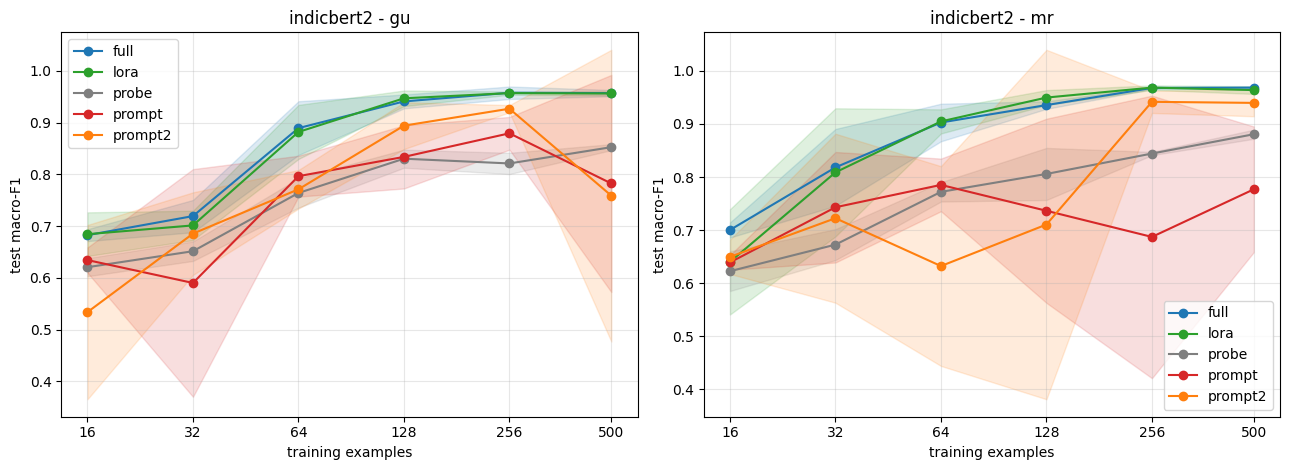


Retention of own full-data F1 (n=500) | indicbert2 | gu


n_train,16,32,64,128,256,500
method,,,,,,
full,0.713,0.752,0.929,0.983,1.001,1.0
lora,0.716,0.733,0.922,0.990,1.001,1.0
probe,0.728,0.764,0.896,0.974,0.963,1.0
prompt,0.811,0.754,1.018,1.066,1.124,1.0
prompt2,0.703,0.903,1.016,1.178,1.222,1.0



Retention of own full-data F1 (n=500) | indicbert2 | mr


n_train,16,32,64,128,256,500
method,,,,,,
full,0.723,0.845,0.932,0.966,0.999,1.0
lora,0.664,0.839,0.939,0.985,1.005,1.0
probe,0.707,0.764,0.877,0.915,0.959,1.0
prompt,0.823,0.956,1.011,0.948,0.885,1.0
prompt2,0.691,0.769,0.673,0.756,1.002,1.0



AULC (mean macro-F1 across training sizes, log scale; higher is better)


method            full   lora  probe  prompt  prompt2
model      lang                                      
indicbert2 gu    0.865  0.861  0.760   0.761    0.784
           mr    0.891  0.886  0.769   0.732    0.759

... (2 outputs left out)


Significance tests (only 3 seeds, so treat p-values as a rough guide)


,lang,n_train,comparison,mean_diff,p_value
0,gu,16,lora vs full,0.0019,0.9465
1,gu,16,prompt vs full,-0.0482,0.0573
2,gu,16,prompt2 vs full,-0.1488,0.2653
3,gu,16,prompt2 vs lora,-0.1507,0.2582
4,gu,16,lora vs prompt,0.0501,0.1677
5,gu,32,lora vs full,-0.0180,0.5012
6,gu,32,prompt vs full,-0.1293,0.4164
7,gu,32,prompt2 vs full,-0.0339,0.5493
8,gu,32,prompt2 vs lora,-0.0159,0.7704
9,gu,32,lora vs prompt,0.1113,0.4742



Best method per training size


,lang,n_train,method,f1_mean
0,gu,16,lora,0.684
1,gu,32,full,0.719
2,gu,64,full,0.889
3,gu,128,lora,0.947
4,gu,256,full,0.958
5,gu,500,full,0.957
6,mr,16,full,0.700
7,mr,32,full,0.818
8,mr,64,lora,0.905
9,mr,128,lora,0.950


In [ ]:
#Cell 2: full analysis, including prompt2

import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import ttest_ind

res = pd.read_csv(RESULTS_PATH)
res = res[res.model == "indicbert2"]
print("runs per method:", res.groupby("method").size().to_dict())

agg = (res.groupby(["model", "lang", "method", "n_train"])
          .agg(f1_mean=("macro_f1", "mean"), f1_std=("macro_f1", "std"),
               acc_mean=("acc", "mean"), runs=("seed", "count")).reset_index())
agg["f1_std"] = agg["f1_std"].fillna(0.0)
agg.to_csv(os.path.join(OUT_DIR, "summary_macro_f1.csv"), index=False)

# ---- Table: macro-F1 mean ± std
for (mk, lang), g in agg.groupby(["model", "lang"]):
    t = (g.assign(txt=lambda d: d.f1_mean.map("{:.3f}".format) + " ± " + d.f1_std.map("{:.3f}".format))
          .pivot(index="method", columns="n_train", values="txt"))
    print(f"\nMacro-F1 (mean ± std over seeds) | {mk} | {lang}")
    display(t)

# ---- Stability check: runs that collapsed to near chance (F1 < 0.6) with 128+ training examples
big = res[res.n_train >= 128]
collapse = big.assign(collapsed=big.macro_f1 < 0.6).groupby(["lang", "method"]).collapsed.agg(["sum", "count"])
collapse.columns = ["collapsed_runs", "total_runs"]
print("\nCollapsed runs (macro-F1 < 0.6) among runs with >=128 training examples:")
display(collapse)

# ---- Learning curves
colors = {"full": "tab:blue", "lora": "tab:green", "prompt": "tab:red", "prompt2": "tab:orange", "probe": "tab:gray"}
groups = list(agg.groupby(["model", "lang"]))
fig, axes = plt.subplots(1, len(groups), figsize=(6.5 * len(groups), 4.8), squeeze=False)
for ax, ((mk, lang), g) in zip(axes[0], groups):
    for method, gm in g.groupby("method"):
        gm = gm.sort_values("n_train")
        ax.plot(gm.n_train, gm.f1_mean, marker="o", label=method, color=colors.get(method))
        ax.fill_between(gm.n_train, gm.f1_mean - gm.f1_std, gm.f1_mean + gm.f1_std, alpha=0.15, color=colors.get(method))
    ax.set_xscale("log", base=2)
    ax.set_xticks(sorted(g.n_train.unique())); ax.set_xticklabels(sorted(g.n_train.unique()))
    ax.set_xlabel("training examples"); ax.set_ylabel("test macro-F1")
    ax.set_title(f"{mk} - {lang}"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "learning_curves_final.png"), dpi=200)
plt.show()

# ---- Retention and AULC
full_n = agg.n_train.max()
base = agg[agg.n_train == full_n].set_index(["model", "lang", "method"]).f1_mean.rename("f1_full")
ret = agg.join(base, on=["model", "lang", "method"])
ret["retention"] = ret.f1_mean / ret.f1_full
ret.to_csv(os.path.join(OUT_DIR, "retention_final.csv"), index=False)
for (mk, lang), g in ret.groupby(["model", "lang"]):
    print(f"\nRetention of own full-data F1 (n={full_n}) | {mk} | {lang}")
    display(g.pivot(index="method", columns="n_train", values="retention").round(3))

def aulc(g):
    g = g.sort_values("n_train")
    x, y = np.log2(g.n_train.values), g.f1_mean.values
    return float(np.sum(np.diff(x) * (y[1:] + y[:-1]) / 2) / (x[-1] - x[0])) if len(x) > 1 else float("nan")
print("\nAULC (mean macro-F1 across training sizes, log scale; higher is better)")
display(agg.groupby(["model", "lang", "method"]).apply(aulc).unstack("method").round(3))

# ---- Cost
cost = (res[res.n_train == res.n_train.max()].groupby(["model", "method"])
        .agg(trainable_params=("trainable_params", "first"), total_params=("total_params", "first"),
             train_time_s=("train_time_s", "mean"), peak_mem_mb=("peak_mem_mb", "mean")).reset_index())
probe_params = cost[cost.method == "probe"].set_index("model").trainable_params
cost["method_specific_params"] = cost.apply(
    lambda r: r.trainable_params if r.method == "full" else r.trainable_params - probe_params[r.model], axis=1)
cost["method_specific_%"] = (100 * cost.method_specific_params / cost.total_params).round(4)
cost.to_csv(os.path.join(OUT_DIR, "cost_final.csv"), index=False)
print("\nCost at the largest training size")
display(cost[["model", "method", "trainable_params", "method_specific_params",
              "method_specific_%", "train_time_s", "peak_mem_mb"]])

# ---- Significance (Welch t-test on per-seed F1)
pairs = [("lora", "full"), ("prompt", "full"), ("prompt2", "full"), ("prompt2", "lora"), ("lora", "prompt")]
rows = []
for (mk, lang, n), g in res.groupby(["model", "lang", "n_train"]):
    for a, b in pairs:
        fa, fb = g[g.method == a].macro_f1.values, g[g.method == b].macro_f1.values
        if len(fa) >= 2 and len(fb) >= 2:
            rows.append(dict(lang=lang, n_train=n, comparison=f"{a} vs {b}",
                             mean_diff=fa.mean() - fb.mean(), p_value=ttest_ind(fa, fb, equal_var=False).pvalue))
sig = pd.DataFrame(rows)
sig.to_csv(os.path.join(OUT_DIR, "significance_final.csv"), index=False)
print("\nSignificance tests (only 3 seeds, so treat p-values as a rough guide)")
display(sig.round(4))

# ---- Best method per training size
best = agg.loc[agg.groupby(["model", "lang", "n_train"]).f1_mean.idxmax(),
               ["lang", "n_train", "method", "f1_mean"]]
print("\nBest method per training size")
display(best.round(3).reset_index(drop=True))

Median macro-F1 over seeds (robust to collapsed runs)


n_train         16     32     64     128    256    500
lang method                                           
gu   full     0.688  0.715  0.889  0.948  0.958  0.956
     lora     0.674  0.697  0.883  0.956  0.958  0.958
     probe    0.617  0.660  0.766  0.835  0.819  0.850
     prompt   0.645  0.711  0.794  0.823  0.894  0.900
     prompt2  0.611  0.693  0.765  0.910  0.928  0.916
mr   full     0.700  0.802  0.883  0.938  0.968  0.968
     lora     0.623  0.749  0.912  0.950  0.970  0.966
     probe    0.606  0.682  0.769  0.833  0.843  0.884
     prompt   0.641  0.739  0.772  0.823  0.723  0.799
     prompt2  0.658  0.758  0.552  0.892  0.952  0.942


Per-seed macro-F1 for the prompt-tuning variants

prompt


seed              0      1      2
lang n_train                     
gu   16       0.645  0.606  0.652
     32       0.336  0.711  0.723
     64       0.794  0.758  0.837
     128      0.823  0.900  0.779
     256      0.843  0.894  0.902
     500      0.540  0.900  0.908
mr   16       0.625  0.652  0.641
     32       0.641  0.739  0.849
     64       0.744  0.772  0.840
     128      0.823  0.849  0.537
     256      0.934  0.405  0.723
     500      0.799  0.649  0.883


prompt2


seed              0      1      2
lang n_train                     
gu   16       0.650  0.340  0.611
     32       0.602  0.693  0.761
     64       0.737  0.765  0.811
     128      0.843  0.910  0.930
     256      0.920  0.928  0.934
     500      0.916  0.433  0.928
mr   16       0.677  0.614  0.658
     32       0.549  0.758  0.861
     64       0.498  0.847  0.552
     128      0.892  0.910  0.331
     256      0.956  0.918  0.952
     500      0.914  0.942  0.964


Median F1 as a fraction of full fine-tuning's median F1 at 500 examples


n_train         16     32     64     128    256    500
lang method                                           
gu   full     0.719  0.748  0.930  0.992  1.002  1.000
     lora     0.705  0.730  0.924  1.000  1.002  1.002
     probe    0.646  0.691  0.802  0.873  0.856  0.889
     prompt   0.675  0.744  0.831  0.861  0.935  0.941
     prompt2  0.639  0.725  0.800  0.952  0.971  0.958
mr   full     0.723  0.828  0.912  0.969  1.000  1.000
     lora     0.644  0.774  0.942  0.981  1.002  0.998
     probe    0.626  0.705  0.795  0.861  0.871  0.913
     prompt   0.662  0.763  0.797  0.851  0.747  0.825
     prompt2  0.680  0.783  0.570  0.921  0.983  0.973

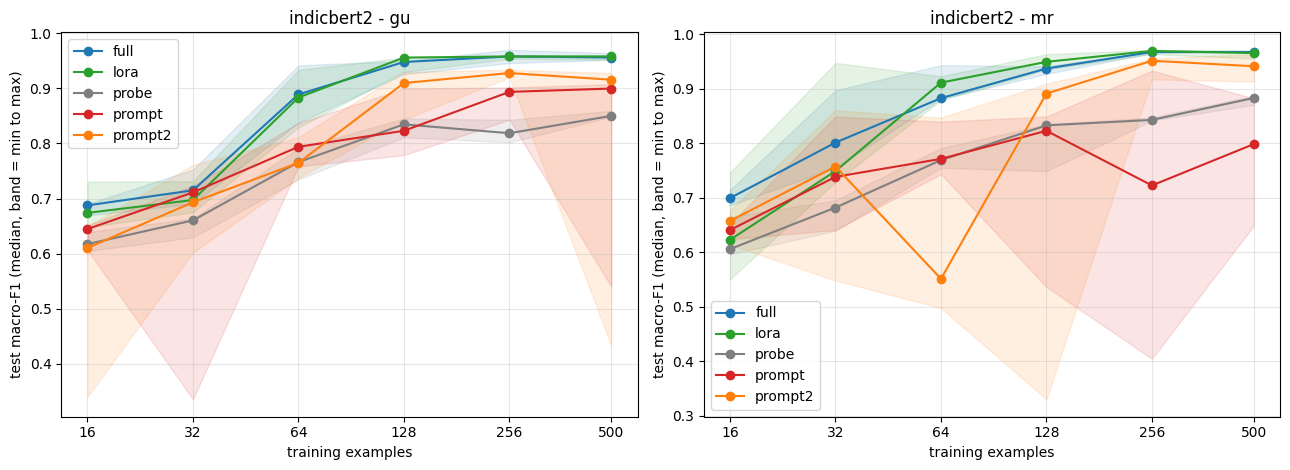

In [ ]:
print("Median macro-F1 over seeds (robust to collapsed runs)")
display(res.pivot_table(index=["lang", "method"], columns="n_train", values="macro_f1", aggfunc="median").round(3))

print("\nPer-seed macro-F1 for the prompt-tuning variants")
for m in ["prompt", "prompt2"]:
    print(f"\n{m}")
    display(res[res.method == m].pivot_table(index=["lang", "n_train"], columns="seed", values="macro_f1").round(3))

ref = res[(res.method == "full") & (res.n_train == res.n_train.max())].groupby("lang").macro_f1.median()
med = res.groupby(["lang", "method", "n_train"]).macro_f1.median().reset_index()
med["vs_full_500"] = med.macro_f1 / med.lang.map(ref)
print("\nMedian F1 as a fraction of full fine-tuning's median F1 at 500 examples")
display(med.pivot_table(index=["lang", "method"], columns="n_train", values="vs_full_500").round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, lang in zip(axes, ["gu", "mr"]):
    for m, g in res[res.lang == lang].groupby("method"):
        s = g.groupby("n_train").macro_f1.agg(["median", "min", "max"]).reset_index()
        ax.plot(s.n_train, s["median"], marker="o", label=m, color=colors[m])
        ax.fill_between(s.n_train, s["min"], s["max"], alpha=0.12, color=colors[m])
    ax.set_xscale("log", base=2)
    ax.set_xticks(sorted(res.n_train.unique())); ax.set_xticklabels(sorted(res.n_train.unique()))
    ax.set_xlabel("training examples"); ax.set_ylabel("test macro-F1 (median, band = min to max)")
    ax.set_title(f"indicbert2 - {lang}"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "learning_curves_median.png"), dpi=200)
plt.show()

## 8. Discussion

**Full data (500 examples).** Full fine-tuning and LoRA performed the same: macro-F1 0.957 vs 0.956 (Gujarati) and 0.969 vs 0.964 (Marathi), with no significant difference at any training size (p ≥ 0.2, Welch t-test, 3 seeds). LoRA trained 294,912 parameters (0.106% of the model) and needed 15.6 s and 1.83 GB of GPU memory per run, against 54.4 s and 5.36 GB for full fine-tuning (about 3.5x faster, 2.9x less memory). A linear probe reached only 0.853 / 0.881, so adapting the encoder matters.

**Low data.** From 500 down to 128 examples, full fine-tuning and LoRA kept 98-99% of their full-data F1 in both languages. At 64 examples they kept 92-93%, and at 16 examples about 66-72%. Performance fell sharply between 64 and 32 examples. At 16-32 examples the differences between methods were within seed noise (e.g. Marathi, 16 examples: full 0.700 vs LoRA 0.640 ± 0.099, p = 0.40). We found no training size at which LoRA or prompt-tuning significantly beat full fine-tuning.

**Prompt-tuning.** Prompt-tuning (20 virtual tokens, 15,360 parameters) was unstable. Counting runs with macro-F1 below 0.55 across all training sizes, 4 of 36 collapsed with the shared learning rate (`prompt`) and 5 of 36 after giving the head its own smaller learning rate (`prompt2`); full fine-tuning, LoRA and the linear probe had none (lowest runs 0.669, 0.551 and 0.596). The collapsed runs occurred at different seeds and training sizes, so they are not tied to one seed. Using medians, `prompt2` reached 0.916 (Gujarati) and 0.942 (Marathi) at 500 examples, which is 96-97% of full fine-tuning's median, compared with 0.900 and 0.799 for `prompt`. We did not test whether `prompt2` is significantly better than `prompt`. Prompt-tuning gave no time or memory saving over LoRA (14.95 s, 1.83 GB), because gradients still pass through the whole network. Its only advantage is trained parameters: about 19x fewer than LoRA.



**Language.** Gujarati and Marathi showed the same pattern. Marathi reached slightly higher scores (0.969 vs 0.957). The two languages are translations of the same reviews, so this is not evidence of how the methods behave on independent data.

## Limitations
* One encoder (IndicBERT v2); mBERT was not run.
* IndicSentiment is translated review text, binary labels only, with ~500 training and 498 test examples per language, so differences of 1-2 points are within noise.
* Only 3 seeds, and 60 uncorrected significance tests were run, so some p < 0.05 results are expected by chance.
* Learning rates were tuned once at n=128 on a 156-example dev set with a small grid. Several best values sat at the grid edge (Marathi: full fine-tuning, LoRA, probe and `prompt2`; Gujarati: probe), so those methods may be slightly under-tuned. `prompt2` was tuned with 2 seeds and a wider grid than the other methods.
* Prompt-tuning instability may partly reflect our training setup (learning rate, fp16, no early stopping) and not the method itself.
* Reviews of the same product appear in both train and test (97% of test rows share a product). Product, aspect and brand tags alone predicted the label below chance (0.40, 0.40, 0.11), so the overlap does not explain the scores.
* The pooler and classifier head are trained in every method except the frozen part of the probe, so "trainable parameters" includes the shared head (592,130).

**Future work:** mBERT and other encoders, more seeds, wider learning-rate grids, and fp32 or vocabulary-based initialisation for prompt-tuning.

## 9. Save example trained models
Trains one LoRA and one Prompt2 model per language (500 examples, seed 0), saves the small trained weights to `OUT_DIR/saved_models`, checks that they reload with the same test score, and downloads them as a zip. These are the files in the `models/` folder of the GitHub repo.

In [ ]:
# ===================== Save trained models for the GitHub repo =====================
# Trains 4 small example models (LoRA and Prompt2, Gujarati and Marathi, 500 examples, seed 0),
# saves them to Google Drive, checks they reload correctly, and downloads one zip file.
#
# Before running this cell in a NEW Colab session, run these earlier cells once (in order):
#   1. %pip -q install ...          (Setup)
#   2. import os, json, gc ...      (imports + Google Drive)
#   3. MODELS = {...}               (Experiment configuration)
#   4. REPO = "ai4bharat/..."       (Data)
#   5. raw = {lang: ...}            (Data)
#   6. def make_splits(lang): ...   (Data)
#   7. TOK = {k: ...}               (Tokenisation)
#   8. def set_seed(seed): ...      (Training and evaluation code)
# =====================================================================================
import os, json, gc, math, time, shutil
import torch
from torch.utils.data import DataLoader
from safetensors.torch import save_file, load_file
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from peft import LoraConfig, PromptTuningConfig, TaskType, get_peft_model
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

MK = "indicbert2"
EPOCHS, BATCH, HEAD_LR = 10, 16, 1e-3
MIN_STEPS = {"full": 100, "lora": 150, "prompt": 300, "prompt2": 300, "probe": 150}   # real values (not smoke test)

# learning rates chosen by the dev-set search (read from Drive; fallback = values in the report)
lr_file = os.path.join(OUT_DIR, "best_lr.json")
BEST_LR = json.load(open(lr_file)) if os.path.exists(lr_file) else {}
FALLBACK = {"gu|lora": 3e-4, "mr|lora": 1e-3, "gu|prompt2": 1e-1, "mr|prompt2": 3e-1}
get_lr = lambda lang, method: BEST_LR.get(f"{MK}|{lang}|{method}", FALLBACK[f"{lang}|{method}"])

def build_peft(method):
    base = AutoModelForSequenceClassification.from_pretrained(MODELS[MK], num_labels=2)
    if method == "lora":
        cfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=8, lora_alpha=16, lora_dropout=0.1,
                         target_modules=["query", "value"])
    else:  # prompt2
        cfg = PromptTuningConfig(task_type=TaskType.SEQ_CLS, num_virtual_tokens=20)
    model = get_peft_model(base, cfg)
    for name, p in model.named_parameters():          # pooler + classifier are trained, as in the experiments
        if ("pooler" in name or "classifier" in name) and "original_module" not in name:
            p.requires_grad = True
    return model

def train_and_keep(lang, method, n=500, seed=0):
    # same training loop as train_run, but the trained model is returned instead of deleted
    set_seed(seed)
    tok = TOK[MK]
    feats = subsample(ENC[(MK, lang, "train")], n, seed)
    lr = get_lr(lang, method)
    model = build_peft(method).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    if method == "prompt2":
        is_head = lambda nm: ("pooler" in nm or "classifier" in nm)
        head_p = [p for nm, p in model.named_parameters() if p.requires_grad and is_head(nm)]
        prompt_p = [p for nm, p in model.named_parameters() if p.requires_grad and not is_head(nm)]
        opt = torch.optim.AdamW([{"params": prompt_p, "lr": lr}, {"params": head_p, "lr": HEAD_LR}], weight_decay=0.01)
    else:
        opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    bs = min(BATCH, len(feats))
    total_steps = max(EPOCHS * math.ceil(len(feats) / bs), MIN_STEPS[method])
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loader = DataLoader(feats, batch_size=bs, shuffle=True, generator=torch.Generator().manual_seed(seed),
                        collate_fn=lambda b: tok.pad(b, return_tensors="pt"))
    step = 0
    model.train()
    while step < total_steps:
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = model(**batch).loss
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            step += 1
            if step >= total_steps:
                break
    acc, f1 = evaluate(model, ENC[(MK, lang, "test")], tok)
    return model, dict(model=MODELS[MK], lang=lang, method=method, n_train=len(feats), seed=seed,
                       lr=lr, steps=total_steps, test_acc=round(acc, 4), test_macro_f1=round(f1, 4))

def save_trained(model, folder, info):
    os.makedirs(folder, exist_ok=True)
    model.save_pretrained(folder)                     # PEFT adapter + config
    # also save every trained tensor (adapter/prompt + pooler + classifier) so nothing is lost
    trained = {n: p.detach().cpu().contiguous() for n, p in model.named_parameters() if p.requires_grad}
    save_file(trained, os.path.join(folder, "trained_weights.safetensors"))
    json.dump(info, open(os.path.join(folder, "run_info.json"), "w"), indent=1)

def load_trained(folder, method):
    model = build_peft(method)
    result = model.load_state_dict(load_file(os.path.join(folder, "trained_weights.safetensors")), strict=False)
    assert not result.unexpected_keys, result.unexpected_keys
    return model.to(DEVICE)

SAVE_DIR = os.path.join(OUT_DIR, "saved_models")      # also kept in your Google Drive
os.makedirs(SAVE_DIR, exist_ok=True)

for method in ["lora", "prompt2"]:
    for lang in ["gu", "mr"]:
        name = f"{method}_{lang}_500_seed0"
        folder = os.path.join(SAVE_DIR, name)
        model, info = train_and_keep(lang, method)
        save_trained(model, folder, info)
        del model; gc.collect(); torch.cuda.empty_cache()
        # check: reload from disk and score the test set again (should give the same F1)
        reloaded = load_trained(folder, method)
        _, f1_again = evaluate(reloaded, ENC[(MK, lang, "test")], TOK[MK])
        del reloaded; gc.collect(); torch.cuda.empty_cache()
        size_mb = sum(os.path.getsize(os.path.join(folder, f)) for f in os.listdir(folder)) / 2**20
        print(f"{name:22s} test macro-F1 = {info['test_macro_f1']:.3f} | after reload = {f1_again:.3f} | {size_mb:.1f} MB")

# zip everything and download it to your computer
shutil.make_archive("/content/saved_models", "zip", SAVE_DIR)
from google.colab import files
files.download("/content/saved_models.zip")
print("\nsaved to", SAVE_DIR, "and downloading saved_models.zip")
